# Part 1: What makes customers spend more? (SweetAroma)

**SweetAroma** is a UK direct-to-consumer e-commerce shop for high-end perfume.
The business wants to know:

1. Which customer background and behaviour factors make customers spend more or less on an order
2. Can we predict how much a new customer will spend, so marketing can focus on high-value customers?

**Data:** 10,000 website orders from July 2025 (`order_july25.csv`) and 20 new customers to predict (`new_customer25.csv`).

| Column | Meaning |
|---|---|
| revenue | Order value in GBP (target) |
| ad_channel | 1 = No ad, 2 = Paid search ad, 3 = Free SEO, 4 = Online ad |
| number_past_order | Number of earlier orders by the customer |
| past_spend | Money the customer spent before (GBP) |
| time_web | Time spent on the website before ordering (seconds) |
| voucher | 1 if a 5% discount voucher was used |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error

sns.set_style("whitegrid")
pd.set_option("display.float_format", "{:.2f}".format)

## 1. Load and check the data

In [2]:
orders = pd.read_csv("../data/order_july25.csv")
new_customers = pd.read_csv("../data/new_customer25.csv")

print(orders.shape)
orders.head()

(10000, 6)


,number_past_order,time_web,voucher,past_spend,ad_channel,revenue
0,2.00,103.00,0.00,28.00,3.00,45.00
1,0.00,139.00,0.00,0.00,4.00,70.00
2,1.00,128.00,0.00,28.00,1.00,37.00
3,0.00,110.00,0.00,0.00,2.00,67.00
4,0.00,157.00,0.00,0.00,4.00,71.00


In [3]:
# summary of each column
orders.describe().T

,count,mean,std,min,25%,50%,75%,max
number_past_order,9884.00,0.77,0.71,0.00,0.00,1.00,1.00,5.00
time_web,9897.00,122.34,24.26,1.00,109.00,126.00,139.00,183.00
voucher,9866.00,0.16,0.36,0.00,0.00,0.00,0.00,1.00
past_spend,9876.00,10.10,13.24,0.00,0.00,6.00,16.00,156.00
ad_channel,9882.00,2.15,1.15,1.00,1.00,2.00,3.00,4.00
revenue,10000.00,55.46,13.28,4.00,47.00,56.00,64.00,106.00


In [4]:
# how many missing values in each column
orders.isnull().sum()

number_past_order    116
time_web             103
voucher              134
past_spend           124
ad_channel           118
revenue                0
dtype: int64

Around 1% of values are missing in each predictor column (revenue has no missing values).
Together this affects about 6% of rows. Because the dataset is large, I drop these rows instead of guessing the values.

In [5]:
orders_clean = orders.dropna().copy()

# ad_channel and voucher are categories, so make them whole numbers
orders_clean["ad_channel"] = orders_clean["ad_channel"].astype(int)
orders_clean["voucher"] = orders_clean["voucher"].astype(int)

print("Rows before:", len(orders))
print("Rows after:", len(orders_clean))
print("Rows removed:", len(orders) - len(orders_clean))

Rows before: 10000
Rows after: 9419
Rows removed: 581


In [6]:
# readable names for the ad channels
channel_names = {1: "No advert", 2: "Paid search ad", 3: "Free SEO", 4: "Online ad"}
orders_clean["channel_name"] = orders_clean["ad_channel"].map(channel_names)

## 2. Exploratory data analysis

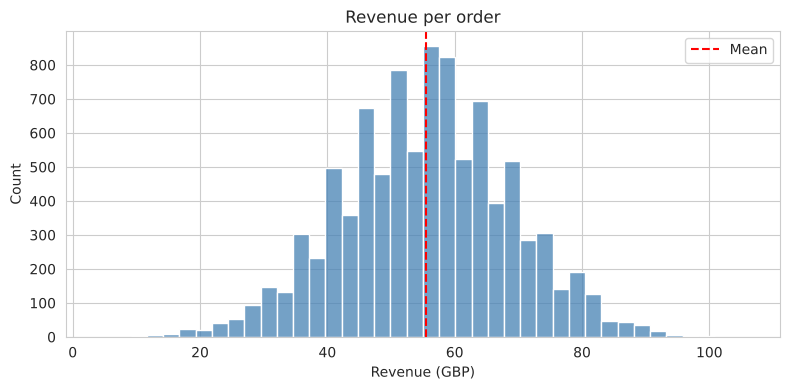

Average order value: £ 55.47


In [7]:
plt.figure(figsize=(8, 4))
sns.histplot(orders_clean["revenue"], bins=40, color="steelblue")
plt.axvline(orders_clean["revenue"].mean(), color="red", linestyle="--", label="Mean")
plt.title("Revenue per order")
plt.xlabel("Revenue (GBP)")
plt.legend()
plt.tight_layout()
plt.savefig("../images/01_revenue_distribution.png", dpi=150)
plt.show()

print("Average order value: £", round(orders_clean["revenue"].mean(), 2))

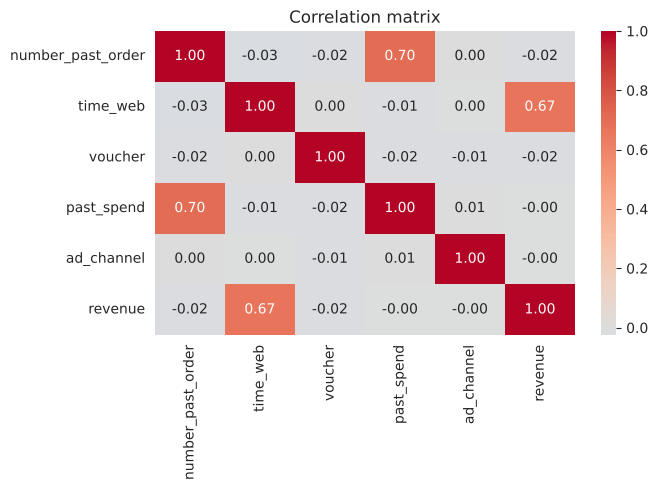

In [8]:
# correlation between all numeric columns
corr = orders_clean.drop(columns="channel_name").corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig("../images/02_correlation_matrix.png", dpi=150)
plt.show()

Only **time on website** has a strong link with revenue (correlation about 0.67).
The other variables are almost uncorrelated with revenue on their own.

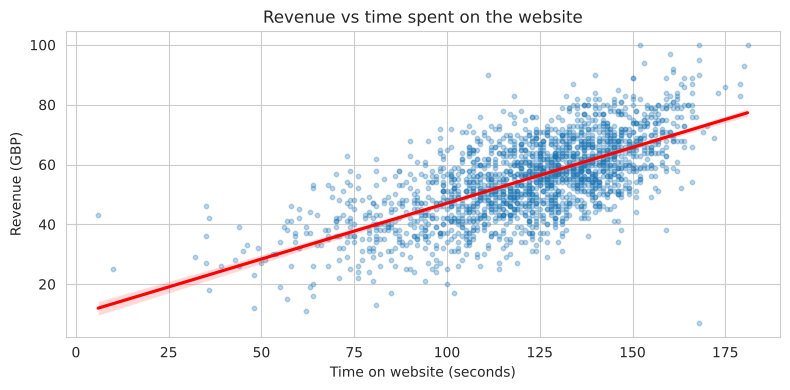

In [9]:
# sample 2000 points so the scatter plot is readable
sample = orders_clean.sample(2000, random_state=1)

plt.figure(figsize=(8, 4))
sns.regplot(data=sample, x="time_web", y="revenue",
            scatter_kws={"alpha": 0.3, "s": 10}, line_kws={"color": "red"})
plt.title("Revenue vs time spent on the website")
plt.xlabel("Time on website (seconds)")
plt.ylabel("Revenue (GBP)")
plt.tight_layout()
plt.savefig("../images/03_revenue_vs_time_web.png", dpi=150)
plt.show()

## 3. Statistical tests: does the ad channel or the voucher change spending?

In [10]:
# average revenue for each ad channel
orders_clean.groupby("channel_name")["revenue"].agg(["mean", "count"]).sort_values("mean", ascending=False)

,mean,count
channel_name,,
No advert,55.55,3880
Paid search ad,55.47,1985
Online ad,55.42,1709
Free SEO,55.38,1845


In [11]:
# one-way ANOVA: are the channel averages different?
groups = [g["revenue"] for _, g in orders_clean.groupby("ad_channel")]
f_stat, p_value = stats.f_oneway(*groups)
print("ANOVA F =", round(f_stat, 3), " p-value =", round(p_value, 3))

if p_value < 0.05:
    print("Ad channels have different average revenue")
else:
    print("No significant difference in average revenue between ad channels")

ANOVA F = 0.086  p-value = 0.968
No significant difference in average revenue between ad channels


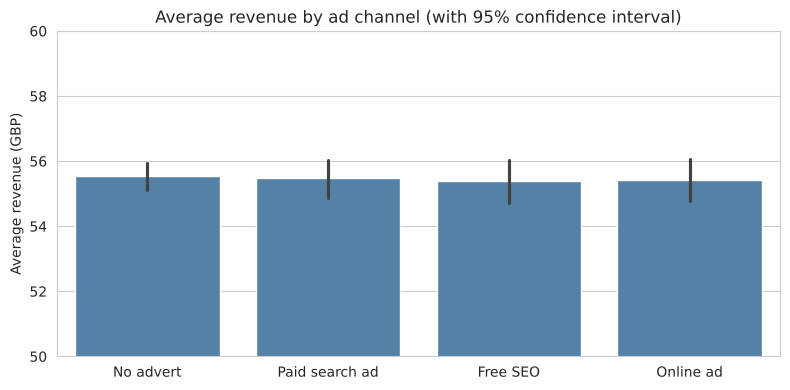

In [12]:
plt.figure(figsize=(8, 4))
sns.barplot(data=orders_clean, x="channel_name", y="revenue", errorbar=("ci", 95),
            order=["No advert", "Paid search ad", "Free SEO", "Online ad"], color="steelblue")
plt.title("Average revenue by ad channel (with 95% confidence interval)")
plt.xlabel("")
plt.ylabel("Average revenue (GBP)")
plt.ylim(50, 60)
plt.tight_layout()
plt.savefig("../images/04_revenue_by_ad_channel.png", dpi=150)
plt.show()

In [13]:
# voucher vs no voucher
print(orders_clean.groupby("voucher")["revenue"].agg(["mean", "count"]))

with_v = orders_clean[orders_clean["voucher"] == 1]["revenue"]
without_v = orders_clean[orders_clean["voucher"] == 0]["revenue"]
t_stat, p_value = stats.ttest_ind(with_v, without_v, equal_var=False)
print("\nWelch t-test: t =", round(t_stat, 3), " p-value =", round(p_value, 3))

         mean  count
voucher             
0       55.57   7960
1       54.93   1459

Welch t-test: t = -1.737  p-value = 0.083


The simple t-test shows voucher orders are about £0.64 lower, but this is only borderline (p ≈ 0.08).
A regression model can check the voucher effect while keeping the other factors fixed.

## 4. Driver analysis: which factors change revenue, holding the others constant?

In [14]:
# linear regression with statsmodels so we can see p-values for each factor
driver_model = smf.ols(
    "revenue ~ time_web + number_past_order + past_spend + voucher + C(ad_channel)",
    data=orders_clean
).fit()

print(driver_model.summary().tables[1])
print("R-squared:", round(driver_model.rsquared, 3))

                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             10.9188      0.557     19.611      0.000       9.827      12.010
C(ad_channel)[T.2]    -0.0285      0.274     -0.104      0.917      -0.565       0.508
C(ad_channel)[T.3]    -0.0875      0.280     -0.312      0.755      -0.637       0.462
C(ad_channel)[T.4]    -0.2277      0.288     -0.791      0.429      -0.792       0.337
time_web               0.3659      0.004     86.605      0.000       0.358       0.374
number_past_order     -0.3978      0.203     -1.957      0.050      -0.796       0.001
past_spend             0.0242      0.011      2.224      0.026       0.003       0.046
voucher               -0.7570      0.283     -2.679      0.007      -1.311      -0.203
R-squared: 0.444


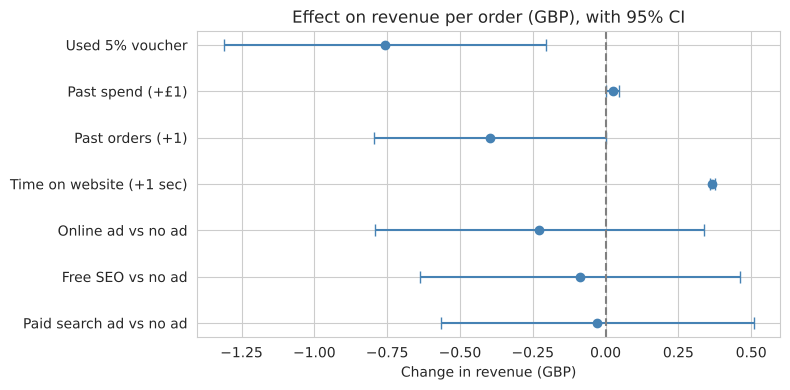

In [15]:
# plot the effect of each factor with its 95% confidence interval
coefs = driver_model.params.drop("Intercept")
ci = driver_model.conf_int().drop("Intercept")

labels = {
    "time_web": "Time on website (+1 sec)",
    "number_past_order": "Past orders (+1)",
    "past_spend": "Past spend (+£1)",
    "voucher": "Used 5% voucher",
    "C(ad_channel)[T.2]": "Paid search ad vs no ad",
    "C(ad_channel)[T.3]": "Free SEO vs no ad",
    "C(ad_channel)[T.4]": "Online ad vs no ad",
}
names = [labels.get(i, i) for i in coefs.index]
errors = [coefs - ci[0], ci[1] - coefs]

plt.figure(figsize=(8, 4))
plt.errorbar(coefs, names, xerr=errors, fmt="o", color="steelblue", capsize=4)
plt.axvline(0, color="grey", linestyle="--")
plt.title("Effect on revenue per order (GBP), with 95% CI")
plt.xlabel("Change in revenue (GBP)")
plt.tight_layout()
plt.savefig("../images/05_revenue_drivers.png", dpi=150)
plt.show()

In [16]:
# what does the time on website effect mean in business terms?
per_second = driver_model.params["time_web"]
print("Each extra 10 seconds on the website adds about £", round(per_second * 10, 2), "to the order")
print("Moving a customer from average to +1 std dev of time on site (about 24 sec) adds about £", round(per_second * orders_clean['time_web'].std(), 2))
print("Using a voucher changes the order by about £", round(driver_model.params["voucher"], 2))

Each extra 10 seconds on the website adds about £ 3.66 to the order
Moving a customer from average to +1 std dev of time on site (about 24 sec) adds about £ 8.85
Using a voucher changes the order by about £ -0.76


## 5. Prediction model for future revenue

The business will judge the model using **RMSE** (root mean squared error), so I compare models with 5-fold cross-validation.
A simple baseline that always predicts the average revenue is included, so we can see how much each model actually helps.

In [17]:
# make dummy columns for ad_channel (it is a category, not a number)
X = pd.get_dummies(orders_clean[["number_past_order", "time_web", "voucher", "past_spend", "ad_channel"]],
                   columns=["ad_channel"], drop_first=True).astype(float)
y = orders_clean["revenue"]

models = {
    "Baseline (always predict average)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = []
for name, model in models.items():
    scores = -cross_val_score(model, X, y, cv=kf, scoring="neg_root_mean_squared_error")
    results.append({"Model": name, "CV RMSE (GBP)": scores.mean(), "Std": scores.std()})

results = pd.DataFrame(results).sort_values("CV RMSE (GBP)")
results

,Model,CV RMSE (GBP),Std
3,Gradient Boosting,9.86,0.13
1,Linear Regression,9.92,0.09
2,Random Forest,10.16,0.16
0,Baseline (always predict average),13.30,0.14


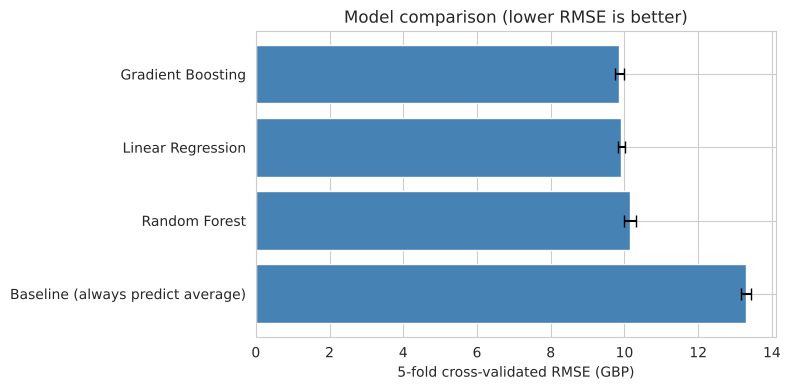

Linear Regression improves on the baseline by 25.4 %


In [18]:
plt.figure(figsize=(8, 4))
plt.barh(results["Model"], results["CV RMSE (GBP)"], xerr=results["Std"], color="steelblue", capsize=4)
plt.gca().invert_yaxis()
plt.title("Model comparison (lower RMSE is better)")
plt.xlabel("5-fold cross-validated RMSE (GBP)")
plt.tight_layout()
plt.savefig("../images/06_model_comparison.png", dpi=150)
plt.show()

base = results.loc[results["Model"].str.startswith("Baseline"), "CV RMSE (GBP)"].values[0]
lr = results.loc[results["Model"] == "Linear Regression", "CV RMSE (GBP)"].values[0]
print("Linear Regression improves on the baseline by", round((base - lr) / base * 100, 1), "%")

**Model choice:** Gradient Boosting and Linear Regression give almost the same error (difference of a few pence).
I choose **Linear Regression** because it is just as accurate, much easier to explain to the marketing team, and every prediction can be traced back to the drivers above.

In [19]:
# check on a hold-out test set as well
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
final_model = LinearRegression().fit(X_train, y_train)
test_rmse = np.sqrt(mean_squared_error(y_test, final_model.predict(X_test)))
print("Hold-out test RMSE: £", round(test_rmse, 2))

# refit on all data for the final predictions
final_model = LinearRegression().fit(X, y)

Hold-out test RMSE: £ 9.89


## 6. Predict revenue for the 20 new customers

In [20]:
X_new = pd.get_dummies(new_customers.drop(columns="order"), columns=["ad_channel"], drop_first=True).astype(float)
X_new = X_new.reindex(columns=X.columns, fill_value=0)

predictions = pd.DataFrame({
    "order": new_customers["order"],
    "predicted_revenue_gbp": np.round(final_model.predict(X_new), 2)
})
predictions.to_csv("../data/predictions_20_customers.csv", index=False)
predictions.sort_values("predicted_revenue_gbp", ascending=False)

,order,predicted_revenue_gbp
15,16,67.20
9,10,65.18
19,20,64.79
6,7,64.35
0,1,64.17
1,2,62.86
18,19,62.12
10,11,61.04
8,9,60.20
14,15,59.87


## 7. Business recommendations

In [21]:
print("Average order value:          £", round(orders_clean["revenue"].mean(), 2))
print("Extra revenue per +10 sec on site: £", round(driver_model.params["time_web"] * 10, 2))
print("Voucher effect per order:      £", round(driver_model.params["voucher"], 2))
print("Ad channel ANOVA p-value:      ", round(stats.f_oneway(*groups).pvalue, 3))
print("Final model CV RMSE:           £", round(lr, 2))

Average order value:          £ 55.47
Extra revenue per +10 sec on site: £ 3.66
Voucher effect per order:      £ -0.76
Ad channel ANOVA p-value:       0.968
Final model CV RMSE:           £ 9.92


1. **Keep customers on the website longer.** Time on site is by far the strongest driver of order value. Better product pages, recommendations and fragrance guides that increase browsing time should be the main focus.
2. **Do not pay extra for ad channels just to increase basket size.** Orders from paid search, free SEO and online adverts spend about the same as orders with no advert. Ad spend should be judged on how many *new* customers it brings, not on order value.
3. **Review the 5% voucher.** Voucher orders are slightly smaller (about £0.76 less per order, holding other factors constant), so the voucher is not increasing spend. It should be tested as a tool to win new customers rather than used for everyone.
4. **Use the model to rank customers, not to forecast exact values.** The model explains about 44% of the variation in revenue and is about £10 off on average, which is good enough to identify likely high-value customers for targeted marketing.

**Limitations:** the data is one month (July) only, so seasonal effects are not captured. Time on site may partly be a result of wanting to buy more, not only a cause, so an A/B test would be needed to prove the effect.